In [2]:
import polars as pl

correlations = pl.read_csv("41586_2020_2314_MOESM4_ESM.csv")
teams = correlations.columns[1:]
array = correlations.drop(correlations.columns[0]).to_numpy()

metadata = pl.read_excel(
    "narps/ImageAnalyses/metadata_files/analysis_pipelines_for_analysis.xlsx",
    read_options={"header_row": 1},
).select(
    pl.col("teamID").str.strip_chars(),
    pl.col("used_fmriprep_data")
    .cast(pl.Utf8)
    .str.strip_chars()
    .str.split(",")
    .list.first()
    .str.replace("Yas", "Yes")  # same manual fix as narps/ImageAnalyses/utils.py
    .eq("Yes")
    .alias("fmriprep"),
)
used_fmriprep = (
    pl.DataFrame({"teamID": teams})
    .join(metadata, on="teamID", how="left", maintain_order="left")["fmriprep"]
    .to_numpy()
    .astype(int)
)

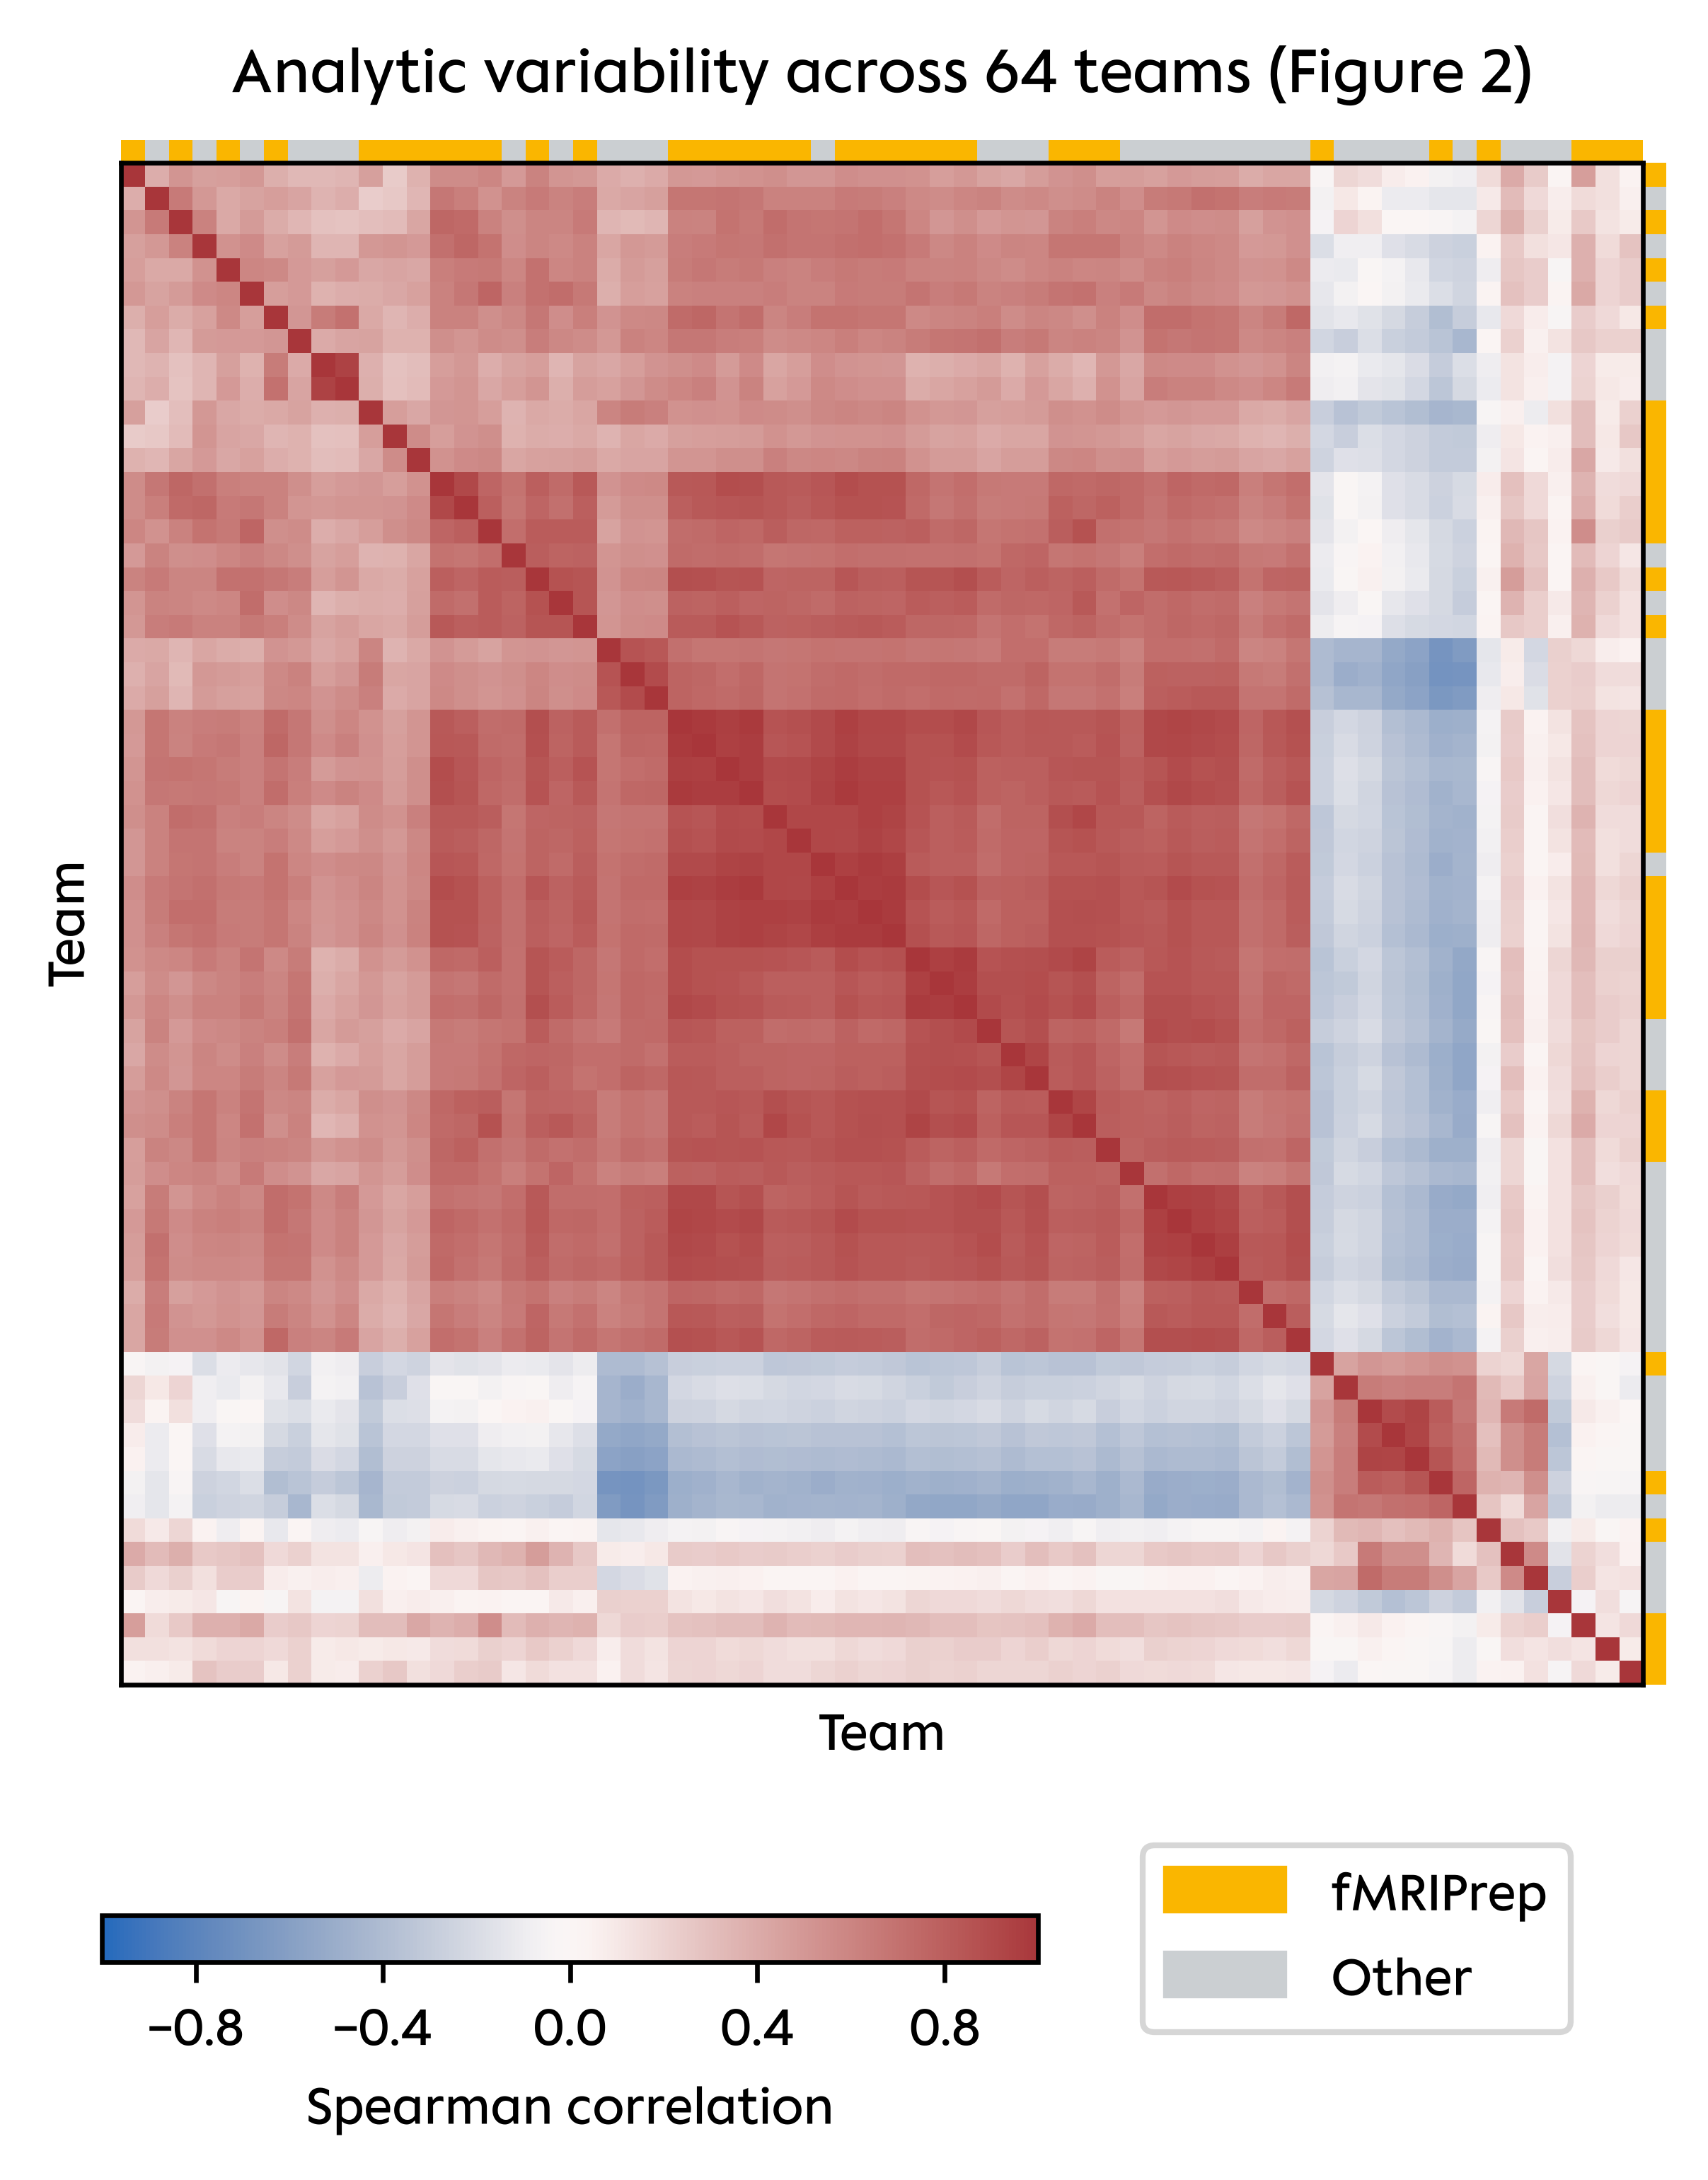

In [4]:
import numpy as np
import seaborn as sns
from matplotlib import pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

font_family = "Charité Text Office"
plt.rcParams.update(
    {
        "font.family": "sans-serif",
        "font.sans-serif": [f"{font_family}"],
        "mathtext.fontset": "custom",
        "mathtext.rm": f"{font_family}",
        "mathtext.it": f"{font_family}:italic",
        "mathtext.bf": f"{font_family}:bold",
        "mathtext.bfit": f"{font_family}:bold:italic",
        "mathtext.sf": f"{font_family}",
    }
)

figure, axes = plt.subplots(
    nrows=1,
    ncols=1,
    figsize=(4, 5),
    dpi=600,
    constrained_layout=True,
)

image = axes.imshow(array, cmap="vlag", vmin=-1, vmax=1, interpolation="nearest")

axes.set_xticks([])
axes.set_yticks([])

MANGO = "#fab600"
PRIME_LGREY = "#cbcfd2"
strip_cmap = ListedColormap([PRIME_LGREY, MANGO])

# strips in axes-fraction coordinates: [x0, y0, width, height]
top = axes.inset_axes((0, 1.00, 1, 0.015), zorder=2)
right = axes.inset_axes((1.00, 0, 0.015, 1), zorder=2)
top.imshow(
    used_fmriprep[np.newaxis, :],
    cmap=strip_cmap,
    vmin=0,
    vmax=1,
    aspect="auto",
    interpolation="nearest",
)
right.imshow(
    used_fmriprep[:, np.newaxis],
    cmap=strip_cmap,
    vmin=0,
    vmax=1,
    aspect="auto",
    interpolation="nearest",
)
for strip in (top, right):
    strip.set_xticks([])
    strip.set_yticks([])
    for spine in strip.spines.values():
        spine.set_visible(False)

axes.set_xlabel("Team")
axes.set_ylabel("Team")

axes.set_title(
    "Analytic variability across 64 teams (Figure 2)",
    pad=12,
)

colorbar = figure.colorbar(
    image,
    ax=axes,
    location="bottom",
    label="Spearman correlation",
    shrink=0.6,  # leave room on the right for the legend
    anchor=(0.0, 0.5),  # align colorbar to the left
)
colorbar.set_ticks([-0.8, -0.4, 0.0, 0.4, 0.8])

colorbar.ax.legend(
    handles=[
        Patch(color=MANGO, label="fMRIPrep"),
        Patch(color=PRIME_LGREY, label="Other"),
    ],
    # ncols=2,
    loc="center left",
    bbox_to_anchor=(1.08, 0.5),  # just right of the colorbar
    frameon=True,
)

figure.savefig("actual.svg", bbox_inches="tight", pad_inches=0, transparent=True)